### Data Science Final Project

## Pengelompokan Pola Gerak dan Aktivitas Manusia Berdasarkan Sinyal Smartphone Menggunakan Agglomerative Hierarchical Clustering


### BUSINESS UNDERSTANDING
#### Masalah

#### Pertanyaan

#### Metode 

#### Metrik

### DATA GATHERING
#### Data Ingestion & Loading
- Mengatasi Duplikat Nama Kolom: Fungsi make_unique() dibuat untuk menambahkan akhiran nomor indeks pada 42 nama fitur yang terduplikasi di file features.txt.   
- Penggabungan Dataset: Data Train (70%) dan Test (30%) digabungkan menjadi satu matriks utuh (10.299 baris x 561 fitur) untuk mempermudah analisis pola unsupervised secara keseluruhan.   

In [13]:
# Import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

In [14]:
# 1. DATA INGESTION & LOADING

print("=== 1. MEMUAT DATASET ===")
base_path = 'UCI HAR Dataset/'

# A. Buka daftar fitur dan buat nama kolom yang unik (mencegah error duplicate names)
features = pd.read_csv(base_path + 'features.txt', sep=r'\s+', header=None, names=['idx', 'name'])

def make_unique(names):
    seen = {}
    unique_names = []
    for name in names:
        if name in seen:
            seen[name] += 1
            unique_names.append(f"{name}_{seen[name]}")
        else:
            seen[name] = 0
            unique_names.append(name)
    return unique_names

column_names = make_unique(features['name'].values)

# B. Buka peta nama aktivitas
activity_labels = pd.read_csv(base_path + 'activity_labels.txt', sep=r'\s+', header=None, names=['id', 'activity_name'])

# C. Buka Data Train dan Test
X_train = pd.read_csv(base_path + 'train/X_train.txt', sep=r'\s+', header=None, names=column_names)
y_train = pd.read_csv(base_path + 'train/y_train.txt', sep=r'\s+', header=None, names=['Activity_ID'])
sub_train = pd.read_csv(base_path + 'train/subject_train.txt', sep=r'\s+', header=None, names=['Subject'])

X_test = pd.read_csv(base_path + 'test/X_test.txt', sep=r'\s+', header=None, names=column_names)
y_test = pd.read_csv(base_path + 'test/y_test.txt', sep=r'\s+', header=None, names=['Activity_ID'])
sub_test = pd.read_csv(base_path + 'test/subject_test.txt', sep=r'\s+', header=None, names=['Subject'])

# D. Penggabungan Data (Train + Test)
X_raw = pd.concat([X_train, X_test], ignore_index=True)
y_raw = pd.concat([y_train, y_test], ignore_index=True)
sub_raw = pd.concat([sub_train, sub_test], ignore_index=True)

# Susun dalam satu DataFrame terpadu
df = X_raw.copy()
df['Subject'] = sub_raw['Subject']
df['Activity_ID'] = y_raw['Activity_ID']
df['Activity'] = df['Activity_ID'].map(dict(zip(activity_labels['id'], activity_labels['activity_name'])))

print(f"Data Berhasil Dimuat! Total Baris: {df.shape[0]}, Total Kolom: {df.shape[1]}")

=== 1. MEMUAT DATASET ===
Data Berhasil Dimuat! Total Baris: 10299, Total Kolom: 564


### CLEANING
#### Data Cleaning & Verifikasi Kualitas
- Verifikasi Integritas: Kode memverifikasi secara eksplisit bahwa dataset UCI HAR bebas dari nilai kosong (missing values) dan baris duplikat.
- Guardrail: Disediakan logika penanganan otomatis (dropna() / drop_duplicates()) jika terdapat anomali data di masa mendatang

In [15]:
# 2. DATA CLEANING & QUALITY CHECK

print("\n=== 2. DATA CLEANING & VERIFIKASI KUALITAS ===")

# A. Cek Missing Values
missing_count = df.isnull().sum().sum()
print(f"Total Missing Values dalam Dataset: {missing_count}")

# B. Cek Baris Duplikat pada Matriks Fitur (X_raw)
duplicate_count = X_raw.duplicated().sum()
print(f"Total Baris Duplikat pada Fitur Sinyal: {duplicate_count}")

# C. Penanganan Jika Terdapat Duplikat/Missing Values (Guardrail)
if missing_count > 0:
    df = df.dropna()
    print("Missing values telah dihapus.")

if duplicate_count > 0:
    df = df.drop_duplicates(subset=column_names)
    print("Baris duplikat telah dibersihkan.")
else:
    print("Data bersih: Tidak memerlukan imputasi atau drop duplikat.")


=== 2. DATA CLEANING & VERIFIKASI KUALITAS ===
Total Missing Values dalam Dataset: 0


Total Baris Duplikat pada Fitur Sinyal: 0
Data bersih: Tidak memerlukan imputasi atau drop duplikat.


### EDA
- Distribusi Aktivitas: Visualisasi countplot mengonfirmasi bahwa 6 kelas aktivitas berada dalam proporsi yang terdistribusi secara relatif seimbang.   
- Eksplorasi Sinyal (Dinamis vs. Statis): Boxplot fitur tBodyAccMag-mean() menunjukkan perbedaan signifikan antara aktivitas dinamis (walking, upstairs, downstairs) yang memiliki energi percepatan tinggi dan aktivitas statis (sitting, standing, laying) dengan energi mendekati nol


=== 3. EXPLORATORY DATA ANALYSIS (EDA) ===


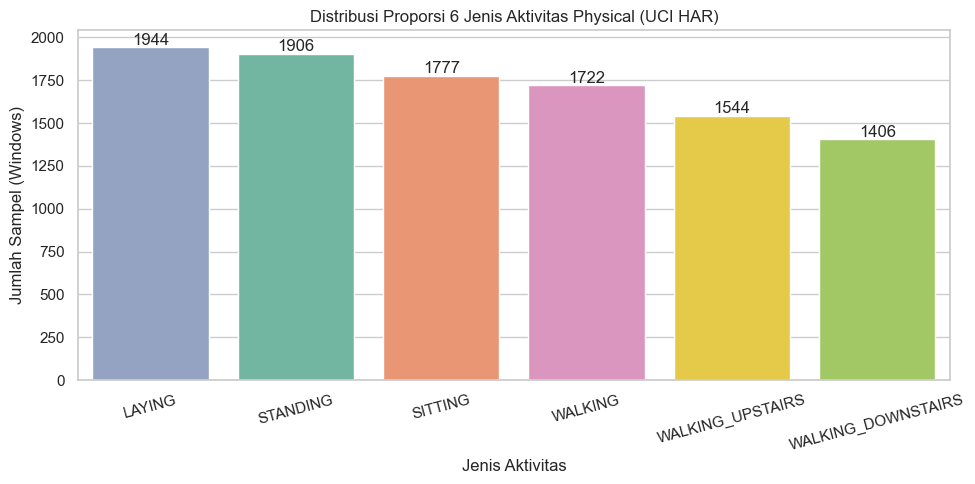

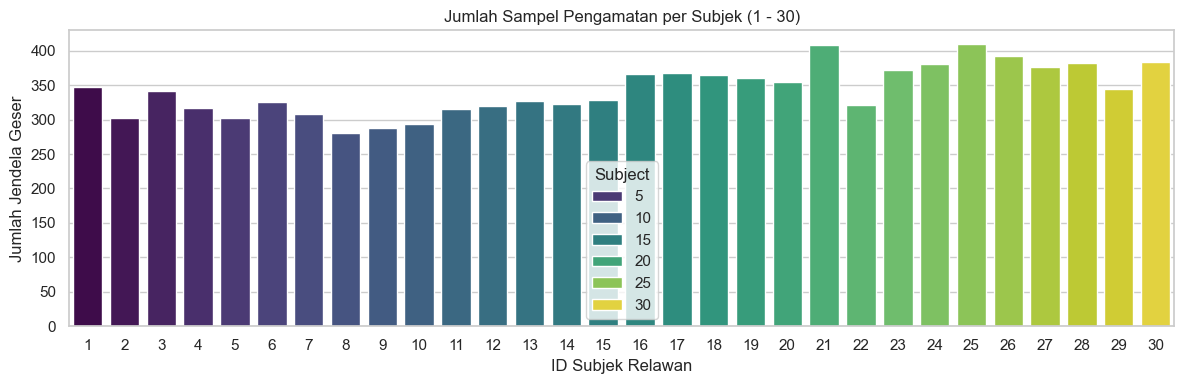

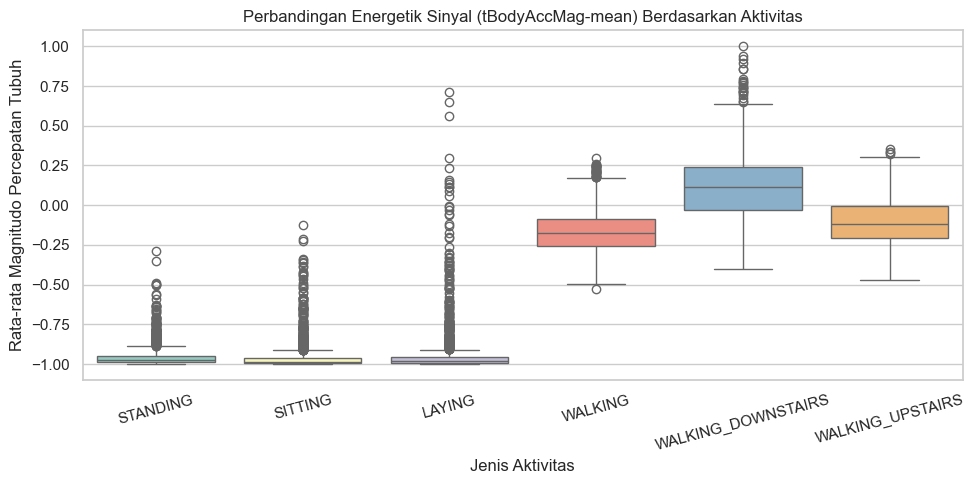

In [16]:
# 3. EXPLORATORY DATA ANALYSIS (EDA)

print("\n=== 3. EXPLORATORY DATA ANALYSIS (EDA) ===")

# A. Visualisasi Distribusi Kelas Aktivitas (Ground Truth)
plt.figure(figsize=(10, 5))
ax = sns.countplot(data=df, x='Activity', hue='Activity', palette='Set2', order=df['Activity'].value_counts().index)
plt.title("Distribusi Proporsi 6 Jenis Aktivitas Physical (UCI HAR)")
plt.xlabel("Jenis Aktivitas")
plt.ylabel("Jumlah Sampel (Windows)")
plt.xticks(rotation=15)

for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points')
plt.tight_layout()
plt.show()

# B. Visualisasi Sebaran Data antar Subjek (30 Relawan)
plt.figure(figsize=(12, 4))
sns.countplot(data=df, x='Subject', hue='Subject', palette='viridis')
plt.title("Jumlah Sampel Pengamatan per Subjek (1 - 30)")
plt.xlabel("ID Subjek Relawan")
plt.ylabel("Jumlah Jendela Geser")
plt.tight_layout()
plt.show()

# C. Eksplorasi Fitur Sinyal: Membedakan Gerak Dinamis vs Statis
# Mengambil variabel magnitudo percepatan tubuh (tBodyAccMag-mean())
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='Activity', y='tBodyAccMag-mean()', hue='Activity', palette='Set3')
plt.title("Perbandingan Energetik Sinyal (tBodyAccMag-mean) Berdasarkan Aktivitas")
plt.xlabel("Jenis Aktivitas")
plt.ylabel("Rata-rata Magnitudo Percepatan Tubuh")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### PREPROCESSING
- Standarisasi (StandardScaler): Mentransformasikan 561 fitur agar memiliki rata-rata $\mu = 0$ dan standar deviasi $\sigma = 1$, memuluskan perhitungan jarak Euclidean pada Agglomerative Hierarchical Clustering.
- Reduksi Dimensi (PCA): Mereduksi 561 fitur berdimensi tinggi menjadi $\sim 60-100$ komponen utama yang merangkum 90% varians data. Langkah ini mempercepat komputasi pengelompokan hierarki serta mereduksi noise multikolinearitas


=== 4. DATA PREPROCESSING ===
Bentuk Matriks Sebelum PCA : (10299, 561)
Bentuk Matriks Setelah PCA  : (10299, 65) (Mempertahankan 90% varians)


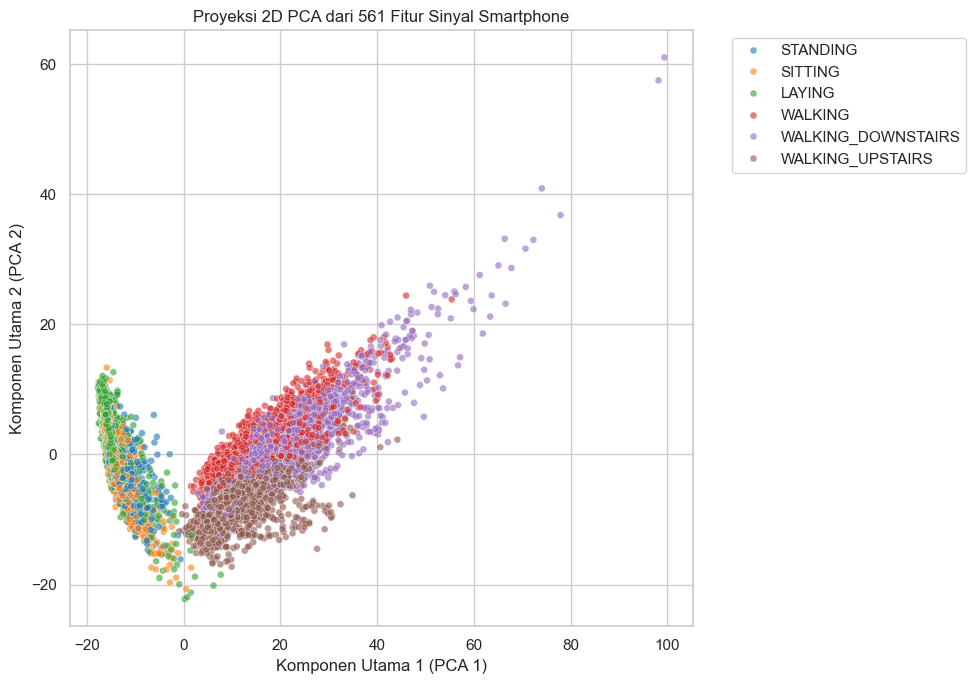

In [17]:
# 4. DATA PREPROCESSING (REDUKSI DIMENSI & SCALING)

print("\n=== 4. DATA PREPROCESSING ===")

# A. Pemisahan Matriks Fitur (X) dan Metadata (y, subject)
X_features = df[column_names].values
y_labels = df['Activity'].values

# B. Standarisasi Fitur (StandardScaler)
# Meskipun data UCI HAR sudah pada [-1, 1], scaling memastikan z-score normalisasi
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_features)

# C. Reduksi Dimensi Menggunakan PCA (Principal Component Analysis)
# Mengecilkan 561 fitur menjadi komponen utama yang menangkap 90% varians
pca = PCA(n_components=0.90, random_state=42)
X_pca = pca.fit_transform(X_scaled)

print(f"Bentuk Matriks Sebelum PCA : {X_scaled.shape}")
print(f"Bentuk Matriks Setelah PCA  : {X_pca.shape} (Mempertahankan 90% varians)")

# D. Visualisasi Proyeksi PCA 2D untuk Evaluasi Pemisahan Klaster Awal
pca_2d = PCA(n_components=2, random_state=42)
X_pca_2d = pca_2d.fit_transform(X_scaled)

df_pca_2d = pd.DataFrame(X_pca_2d, columns=['PCA_1', 'PCA_2'])
df_pca_2d['Activity'] = y_labels

plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=df_pca_2d, 
    x='PCA_1', 
    y='PCA_2', 
    hue='Activity', 
    palette='tab10', 
    alpha=0.6, 
    s=25
)
plt.title("Proyeksi 2D PCA dari 561 Fitur Sinyal Smartphone")
plt.xlabel("Komponen Utama 1 (PCA 1)")
plt.ylabel("Komponen Utama 2 (PCA 2)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()